Train NaN: 0
Test NaN: 0


c:\Users\Admin\2026-\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


SHAP shape: (206, 53)
Test shape: (206, 53)


C:\Users\Admin\AppData\Local\Temp\ipykernel_20508\1139581470.py:196: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


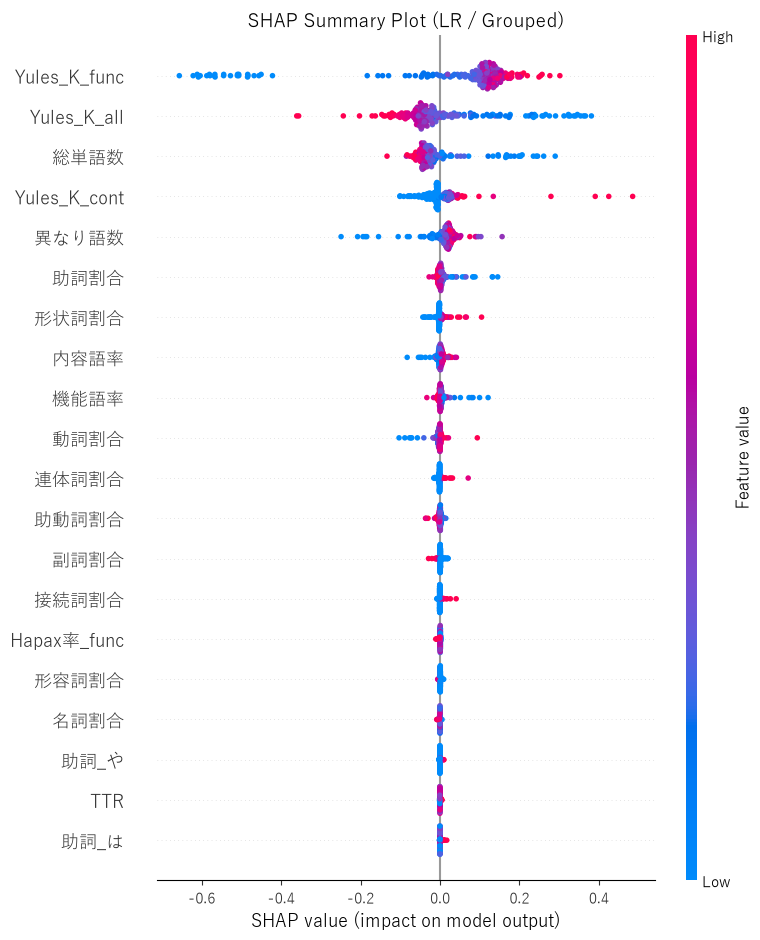

Beeswarm Plot保存: c:\Users\Admin\2026-\one-sentence\AI確信度\SHAP_summary_Grouped.png

SHAP分析完了
グループ別結果: c:\Users\Admin\2026-\one-sentence\AI確信度\SHAP_group_results.csv
特徴量別結果: c:\Users\Admin\2026-\one-sentence\AI確信度\SHAP_feature_details.csv
グループ数: 5
特徴量数: 53
対象文数: 206


In [4]:

import os
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# ==========================================
# 1. 特徴量グループ
# ==========================================

feature_groups = {
    "機能語": [
        "機能語率", "助詞割合", "助動詞割合",
        "連体詞割合", "接続詞割合",
        "助詞_と", "助詞_は", "助詞_の", "助詞_で",
        "助詞_て", "助詞_に", "助詞_や", "助詞_を",
        "助詞_ば", "助詞_が", "助詞_も", "助詞_つつ",
        "助詞_から", "助詞_など", "助詞_へ", "助詞_まで",
        "助詞_か", "助詞_たり", "助詞_だけ",
        "助詞_ながら", "助詞_より"
    ],

    "内容語": [
        "内容語率", "名詞割合", "動詞割合",
        "形容詞割合", "形状詞割合", "副詞割合",
        "感動詞割合"
    ],

    "語彙多様性・反復": [
        "異なり語数", "TTR",
        "Hapax率_all", "Yules_K_all",
        "Hapax率_func", "Yules_K_func",
        "Hapax率_cont", "Yules_K_cont"
    ],

    "文長・文構造": [
        "総単語数", "文長標準偏差",
        "最大文長", "平均文長"
    ],

    "表記・句読点": [
        "ひらがな率", "カタカナ率",
        "漢字率", "英数字率",
        "読点頻度", "句点頻度",
        "感嘆符数", "疑問符数"
    ]
}

feature_mode = "Grouped"

# ==========================================
# 2. データ読み込み
# ==========================================

current_dir = os.getcwd()

if not current_dir.endswith("AI確信度"):
    current_dir = os.path.join(current_dir, "AI確信度")

train_path = os.path.join(
    current_dir,
    "train_Confidence-Level_one_sentence_stylometry_features.csv"
)

test_path = os.path.join(
    current_dir,
    "test_Confidence-Level_one_sentence_stylometry_features.csv"
)

df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)

# ==========================================
# 3. 特徴量の準備
# ==========================================

base_features = list(dict.fromkeys(
    feature
    for features in feature_groups.values()
    for feature in features
))

# 不足している特徴量を0で追加
for col in base_features:
    if col not in df_train.columns:
        df_train[col] = 0.0

    if col not in df_test.columns:
        df_test[col] = 0.0

# 数値型に変換
df_train[base_features] = df_train[base_features].apply(
    pd.to_numeric, errors="coerce"
)

df_test[base_features] = df_test[base_features].apply(
    pd.to_numeric, errors="coerce"
)

# NaN・正負の無限大を0に置換
df_train[base_features] = (
    df_train[base_features]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

df_test[base_features] = (
    df_test[base_features]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

# 欠損値が残っていないか確認
print("Train NaN:", df_train[base_features].isna().sum().sum())
print("Test NaN:", df_test[base_features].isna().sum().sum())
# ==========================================
# 4. LRの学習
# ==========================================

X_train = df_train[base_features]
X_test = df_test[base_features]

y_train = df_train["label"]

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(
    max_iter=5000,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train_scaled, y_train)

ai_index = list(model.classes_).index("AI")

# ==========================================
# 5. SHAP計算
# ==========================================

def predict_ai_probability(X):
    X = np.asarray(X, dtype=float)
    return model.predict_proba(X)[:, ai_index]


# 学習データから背景データを抽出
background = (
    df_train[base_features]
    .sample(
        n=min(100, len(df_train)),
        random_state=42
    )
    .to_numpy()
)

background_scaled = scaler.transform(background)

explainer = shap.Explainer(
    predict_ai_probability,
    shap.maskers.Independent(
        background,
        max_samples=len(background)
    ),
    algorithm="permutation"
)

# テストデータのAI確率に対するSHAP値
shap_result = explainer(
    X_test.to_numpy(),
    max_evals=10 * (2 * len(base_features) + 1)
)

shap_values = np.asarray(shap_result.values)

# 形状確認
print("SHAP shape:", shap_values.shape)
print("Test shape:", X_test.shape)

if shap_values.shape != X_test.shape:
    raise ValueError(
        "SHAP値とテストデータの形状が一致していません。"
    )

# ==========================================
# 6. SHAP Beeswarm Plot
# ==========================================

plt.figure(figsize=(12, 10))

shap.summary_plot(
    shap_values,
    X_test,
    feature_names=base_features,
    max_display=20,
    plot_type="dot",
    show=False
)

plt.title(
    "SHAP Summary Plot (LR / Grouped)",
    fontsize=14
)

plt.tight_layout()

output_path = os.path.join(
    current_dir,
    "SHAP_summary_Grouped.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Beeswarm Plot保存:", output_path)

# ==========================================
# 7. グループ別・特徴量別に集約
# ==========================================

group_rows = []
feature_rows = []

feature_index = {
    name: i for i, name in enumerate(base_features)
}

for row_idx, row in df_test.iterrows():

    values = shap_values[row_idx]

    doc_id = (
        row["doc_id"]
        if "doc_id" in df_test.columns
        else (
            row["filename"]
            if "filename" in df_test.columns
            else row_idx
        )
    )

    label = row["label"]

    sent_order = (
        row["sent_order"]
        if "sent_order" in df_test.columns
        else row_idx + 1
    )

    # 特徴量別SHAP値
    for feature in base_features:

        j = feature_index[feature]

        belonging_group = next(
            group
            for group, features in feature_groups.items()
            if feature in features
        )

        feature_rows.append({
            "doc_id": doc_id,
            "sent_order": sent_order,
            "label": label,
            "特徴量": feature,
            "所属グループ": belonging_group,
            "SHAP値": values[j],
            "SHAP絶対値": abs(values[j])
        })

    # グループ別SHAP値
    for group, features in feature_groups.items():

        indices = [
            feature_index[f]
            for f in features
        ]

        group_values = values[indices]

        group_rows.append({
            "doc_id": doc_id,
            "sent_order": sent_order,
            "label": label,
            "特徴量グループ": group,
            "グループSHAP合計": np.sum(group_values),
            "グループSHAP絶対値合計": np.sum(
                np.abs(group_values)
            ),
            "グループ内平均絶対SHAP値": np.mean(
                np.abs(group_values)
            ),
            "グループ内特徴量数": len(features)
        })

# ==========================================
# 8. CSV保存
# ==========================================

df_group_shap = pd.DataFrame(group_rows)
df_feature_shap = pd.DataFrame(feature_rows)

group_path = os.path.join(
    current_dir,
    "SHAP_group_results.csv"
)

feature_path = os.path.join(
    current_dir,
    "SHAP_feature_details.csv"
)

df_group_shap.to_csv(
    group_path,
    index=False,
    encoding="utf-8-sig"
)

df_feature_shap.to_csv(
    feature_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nSHAP分析完了")
print("グループ別結果:", group_path)
print("特徴量別結果:", feature_path)
print("グループ数:", len(feature_groups))
print("特徴量数:", len(base_features))
print("対象文数:", len(df_test))


Train NaN: 0
Test NaN: 0
RF学習完了
学習データ数: 721
特徴量数: 53


c:\Users\Admin\2026-\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\Admin\2026-\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\Admin\2026-\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\Admin\2026-\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\Admin\2026-\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  

SHAP shape: (206, 53)
Test shape: (206, 53)


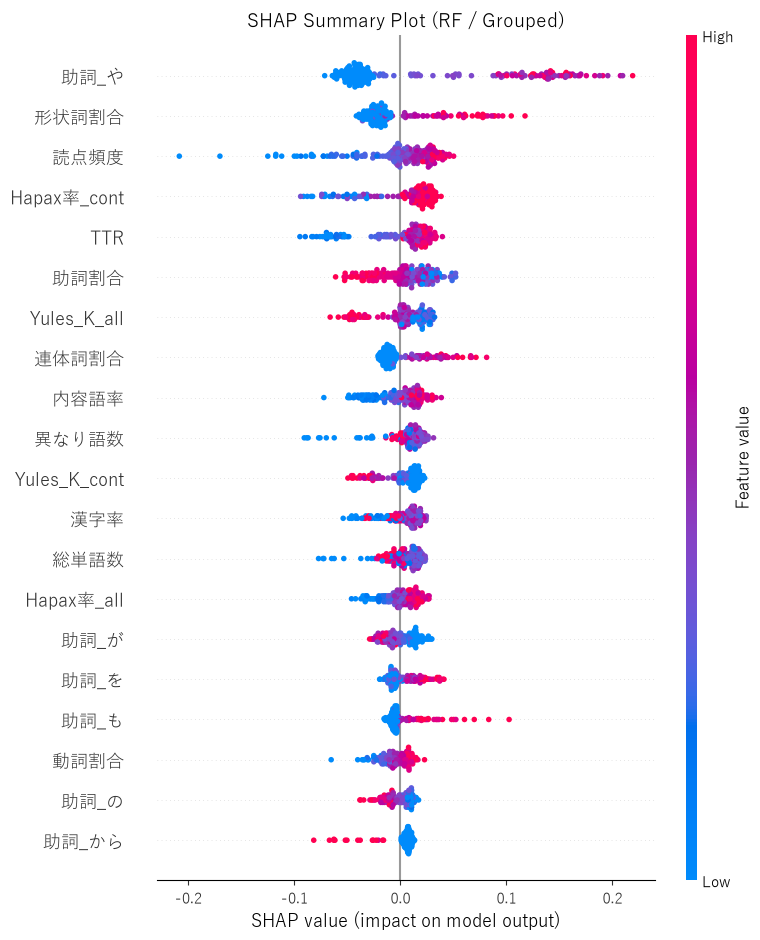

Beeswarm Plot保存: c:\Users\Admin\2026-\one-sentence\AI確信度\SHAP_summary_Grouped_RF.png

RF SHAP分析完了
グループ別結果: c:\Users\Admin\2026-\one-sentence\AI確信度\SHAP_group_results_RF.csv
特徴量別結果: c:\Users\Admin\2026-\one-sentence\AI確信度\SHAP_feature_details_RF.csv
グループ数: 5
特徴量数: 53
対象文数: 206


In [5]:
import os
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier

# ==========================================
# 1. 特徴量グループ
# ==========================================

feature_groups = {
    "機能語": [
        "機能語率", "助詞割合", "助動詞割合",
        "連体詞割合", "接続詞割合",
        "助詞_と", "助詞_は", "助詞_の", "助詞_で",
        "助詞_て", "助詞_に", "助詞_や", "助詞_を",
        "助詞_ば", "助詞_が", "助詞_も", "助詞_つつ",
        "助詞_から", "助詞_など", "助詞_へ", "助詞_まで",
        "助詞_か", "助詞_たり", "助詞_だけ",
        "助詞_ながら", "助詞_より"
    ],

    "内容語": [
        "内容語率", "名詞割合", "動詞割合",
        "形容詞割合", "形状詞割合", "副詞割合",
        "感動詞割合"
    ],

    "語彙多様性・反復": [
        "異なり語数", "TTR",
        "Hapax率_all", "Yules_K_all",
        "Hapax率_func", "Yules_K_func",
        "Hapax率_cont", "Yules_K_cont"
    ],

    "文長・文構造": [
        "総単語数", "文長標準偏差",
        "最大文長", "平均文長"
    ],

    "表記・句読点": [
        "ひらがな率", "カタカナ率",
        "漢字率", "英数字率",
        "読点頻度", "句点頻度",
        "感嘆符数", "疑問符数"
    ]
}

feature_mode = "Grouped"

# ==========================================
# 2. データ読み込み
# ==========================================

current_dir = os.getcwd()

if not current_dir.endswith("AI確信度"):
    current_dir = os.path.join(current_dir, "AI確信度")

train_path = os.path.join(
    current_dir,
    "train_Confidence-Level_one_sentence_stylometry_features.csv"
)

test_path = os.path.join(
    current_dir,
    "test_Confidence-Level_one_sentence_stylometry_features.csv"
)

df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)

# ==========================================
# 3. 特徴量の準備
# ==========================================

base_features = list(dict.fromkeys(
    feature
    for features in feature_groups.values()
    for feature in features
))

# 不足している特徴量を0で追加
for col in base_features:
    if col not in df_train.columns:
        df_train[col] = 0.0

    if col not in df_test.columns:
        df_test[col] = 0.0

# 数値型に変換
df_train[base_features] = df_train[base_features].apply(
    pd.to_numeric, errors="coerce"
)

df_test[base_features] = df_test[base_features].apply(
    pd.to_numeric, errors="coerce"
)

# NaN・正負の無限大を0に置換
df_train[base_features] = (
    df_train[base_features]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

df_test[base_features] = (
    df_test[base_features]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

# 欠損値確認
print("Train NaN:", df_train[base_features].isna().sum().sum())
print("Test NaN:", df_test[base_features].isna().sum().sum())

# ==========================================
# 4. RFの学習
# ==========================================

X_train = df_train[base_features]
X_test = df_test[base_features]

y_train = df_train["label"]

model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

ai_index = list(model.classes_).index("AI")

print("RF学習完了")
print("学習データ数:", len(X_train))
print("特徴量数:", len(base_features))

# ==========================================
# 5. SHAP計算
# ==========================================

def predict_ai_probability(X):
    X = np.asarray(X, dtype=float)
    return model.predict_proba(X)[:, ai_index]


# 学習データから背景データを抽出
background = (
    X_train
    .sample(
        n=min(100, len(X_train)),
        random_state=42
    )
    .to_numpy()
)

explainer = shap.Explainer(
    predict_ai_probability,
    shap.maskers.Independent(
        background,
        max_samples=len(background)
    ),
    algorithm="permutation"
)

# テストデータのAI確率に対するSHAP値
shap_result = explainer(
    X_test.to_numpy(),
    max_evals=10 * (2 * len(base_features) + 1)
)

shap_values = np.asarray(shap_result.values)

# 形状確認
print("SHAP shape:", shap_values.shape)
print("Test shape:", X_test.shape)

if shap_values.shape != X_test.shape:
    raise ValueError(
        "SHAP値とテストデータの形状が一致していません。"
    )

# ==========================================
# 6. SHAP Beeswarm Plot
# ==========================================

plt.figure(figsize=(12, 10))

shap.summary_plot(
    shap_values,
    X_test,
    feature_names=base_features,
    max_display=20,
    plot_type="dot",
    show=False
)

plt.title(
    "SHAP Summary Plot (RF / Grouped)",
    fontsize=14
)

plt.tight_layout()

output_path = os.path.join(
    current_dir,
    "SHAP_summary_Grouped_RF.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Beeswarm Plot保存:", output_path)

# ==========================================
# 7. グループ別・特徴量別に集約
# ==========================================

group_rows = []
feature_rows = []

feature_index = {
    name: i for i, name in enumerate(base_features)
}

for row_idx, (_, row) in enumerate(df_test.iterrows()):

    values = shap_values[row_idx]

    doc_id = (
        row["doc_id"]
        if "doc_id" in df_test.columns
        else (
            row["filename"]
            if "filename" in df_test.columns
            else row_idx
        )
    )

    label = row["label"]

    sent_order = (
        row["sent_order"]
        if "sent_order" in df_test.columns
        else row_idx + 1
    )

    # 特徴量別SHAP値
    for feature in base_features:

        j = feature_index[feature]

        belonging_group = next(
            group
            for group, features in feature_groups.items()
            if feature in features
        )

        feature_rows.append({
            "doc_id": doc_id,
            "sent_order": sent_order,
            "label": label,
            "特徴量": feature,
            "所属グループ": belonging_group,
            "SHAP値": values[j],
            "SHAP絶対値": abs(values[j])
        })

    # グループ別SHAP値
    for group, features in feature_groups.items():

        indices = [
            feature_index[f]
            for f in features
        ]

        group_values = values[indices]

        group_rows.append({
            "doc_id": doc_id,
            "sent_order": sent_order,
            "label": label,
            "特徴量グループ": group,
            "グループSHAP合計": np.sum(group_values),
            "グループSHAP絶対値合計": np.sum(
                np.abs(group_values)
            ),
            "グループ内平均絶対SHAP値": np.mean(
                np.abs(group_values)
            ),
            "グループ内特徴量数": len(features)
        })

# ==========================================
# 8. CSV保存
# ==========================================

df_group_shap = pd.DataFrame(group_rows)
df_feature_shap = pd.DataFrame(feature_rows)

group_path = os.path.join(
    current_dir,
    "SHAP_group_results_RF.csv"
)

feature_path = os.path.join(
    current_dir,
    "SHAP_feature_details_RF.csv"
)

df_group_shap.to_csv(
    group_path,
    index=False,
    encoding="utf-8-sig"
)

df_feature_shap.to_csv(
    feature_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nRF SHAP分析完了")
print("グループ別結果:", group_path)
print("特徴量別結果:", feature_path)
print("グループ数:", len(feature_groups))
print("特徴量数:", len(base_features))
print("対象文数:", len(df_test))
